<a href="https://colab.research.google.com/github/deswaazhar147-pixel/klasifikasi_wine/blob/main/UTS_DataMining_Klasifikasi_Wine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UTS Data Mining: Klasifikasi Kualitas Anggur (Wine Quality)

**Desmiwa Azhar_2404010003**

**Statistika Terapan dan Komputasi, UNNES** | Mata kuliah Data Mining | Take Home Test Ganjil 2026/2027

**Tujuan.** Membuat model klasifikasi yang memprediksi `quality` anggur dari 11 fitur kimia memakai `data_training.csv`, lalu memprediksi `data_testing.csv` dan menyimpannya dalam format `hasilprediksi_[3 digit NIM].csv`.

**Alur notebook** : 1) Persiapan Data, 2) Pembersihan Data, 3) Pembuatan Model, 4) Evaluasi, 5) Simpan Model dan Deployment, 6) Hasil Prediksi, 7) Kesimpulan.

**Catatan penting**
- Semua proses acak memakai `random_state=42` dan path file bersifat relatif, sehingga hasil dapat diulang.
- Data testing **tidak punya label**, jadi akurasi di data testing tidak dapat dihitung. Semua angka performa di notebook berasal dari *cross-validation* dan *hold-out* pada data training.

In [24]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate, RandomizedSearchCV, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
print("Library siap dipakai.")

Library siap dipakai.


## 1. Persiapan Data

Pada bagian ini kita memuat dataset training dan testing, melihat dimensi, tipe data, dan contoh barisnya, lalu memisahkan fitur dan target. Kolom `Id` hanya penanda baris, jadi **tidak dipakai sebagai fitur** dan disimpan terpisah untuk file hasil prediksi.

> Catatan: file `data_training.csv` dan `data_testing.csv` diletakkan satu folder dengan notebook ini.

In [25]:
train = pd.read_csv("data_training.csv")
test = pd.read_csv("data_testing.csv")

print("Dimensi data training:", train.shape)
print("Dimensi data testing :", test.shape)
print("\nTipe data (training):")
print(train.dtypes)
print("\nKolom yang ada di training tetapi tidak ada di testing:", set(train.columns) - set(test.columns))
train.head()

Dimensi data training: (857, 13)
Dimensi data testing : (286, 12)

Tipe data (training):
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
Id                        int64
dtype: object

Kolom yang ada di training tetapi tidak ada di testing: {'quality'}


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.3,0.740,0.08,1.7,0.094,10.0,45.0,0.99576,3.24,0.50,9.8,5,1366
1,8.1,0.575,0.22,2.1,0.077,12.0,65.0,0.99670,3.29,0.51,9.2,5,103
2,10.1,0.430,0.40,2.6,0.092,13.0,52.0,0.99834,3.22,0.64,10.0,7,942
3,12.9,0.500,0.55,2.8,0.072,7.0,24.0,1.00012,3.09,0.68,10.9,6,811
4,8.4,0.360,0.32,2.2,0.081,32.0,79.0,0.99640,3.30,0.72,11.0,6,918


In [26]:
test.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,Id
0,6.8,0.61,0.04,1.5,0.057,5.0,10.0,0.99525,3.42,0.60,9.500000,222
1,6.9,0.84,0.21,4.1,0.074,16.0,65.0,0.99842,3.53,0.72,9.233333,1514
2,7.0,0.58,0.12,1.9,0.091,34.0,124.0,0.99560,3.44,0.48,10.500000,417
3,7.8,0.48,0.68,1.7,0.415,14.0,32.0,0.99656,3.09,1.06,9.100000,754
4,12.5,0.60,0.49,4.3,0.100,5.0,14.0,1.00100,3.25,0.74,11.900000,516


In [27]:
TARGET = "quality"
ID_COL = "Id"
FEATURES = [col for col in test.columns if col != ID_COL]   # 11 fitur kimia

X = train[FEATURES]            # fitur training (tanpa Id dan tanpa quality)
y = train[TARGET]              # target
X_test = test[FEATURES]        # fitur testing (tanpa Id)
id_test = test[ID_COL].copy()  # Id testing disimpan untuk file hasil prediksi

print("Jumlah fitur:", len(FEATURES))
print(FEATURES)
print("X:", X.shape, "| y:", y.shape, "| X_test:", X_test.shape, "| id_test:", id_test.shape)
assert ID_COL not in FEATURES

Jumlah fitur: 11
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
X: (857, 11) | y: (857,) | X_test: (286, 11) | id_test: (286,)


### Interpretasi Bagian 1

- Data training berisi **857 baris dan 13 kolom**, data testing **286 baris dan 12 kolom**. Satu-satunya kolom yang hanya ada di training adalah `quality`, yaitu target yang akan diprediksi.
- Ada **11 fitur kimia** bertipe angka desimal (`float64`). Target `quality` bertipe bilangan bulat, sehingga masalah ini diperlakukan sebagai **klasifikasi multikelas**.
- Kolom `Id` hanyalah penanda baris, bukan sifat kimia anggur. Jika dipakai sebagai fitur, model bisa belajar pola yang tidak bermakna. Karena itu `Id` dikeluarkan dari `X` dan `X_test`, lalu `Id` testing disimpan di `id_test` untuk file hasil prediksi.

## 2. Pembersihan Data

### 2.1 Missing value dan data duplikat

In [28]:
print("Missing value training:", train.isna().sum().sum())
print("Missing value testing :", test.isna().sum().sum())

print("\nBaris duplikat penuh (termasuk Id) -> training:", train.duplicated().sum(), "| testing:", test.duplicated().sum())

# Id pasti unik, jadi duplikat sebenarnya perlu dicek TANPA kolom Id
dup_train = train.duplicated(subset=FEATURES, keep=False)
dup_test = test.duplicated(subset=FEATURES).sum()
print("Baris duplikat tanpa Id -> training (baris ke-2 dst):", train.duplicated(subset=FEATURES).sum(),
      "| testing:", dup_test)

# Apakah baris kembar punya label yang bertentangan?
grup = train[dup_train].groupby(FEATURES)[TARGET].nunique()
print("Kelompok baris kembar di training:", len(grup), "| yang labelnya bertentangan:", int((grup > 1).sum()))

# Berapa baris testing yang fiturnya identik dengan baris training?
overlap = test.merge(train[FEATURES].drop_duplicates(), on=FEATURES, how="inner")
print("Baris testing yang fiturnya identik dengan suatu baris training:", len(overlap))

Missing value training: 0
Missing value testing : 0

Baris duplikat penuh (termasuk Id) -> training: 0 | testing: 0
Baris duplikat tanpa Id -> training (baris ke-2 dst): 76 | testing: 4
Kelompok baris kembar di training: 69 | yang labelnya bertentangan: 0
Baris testing yang fiturnya identik dengan suatu baris training: 45


### Interpretasi Bagian 2.1 (Missing value dan duplikat)

- **Tidak ada missing value** di data training maupun testing, jadi imputasi atau penghapusan baris tidak diperlukan.
- Tidak ada baris yang duplikat secara penuh karena `Id` selalu berbeda. Namun jika `Id` diabaikan, ternyata ada **76 baris training** (dalam 69 kelompok) yang 11 fiturnya persis sama, dan 4 baris seperti itu di testing. Semua kelompok kembar di training punya label yang **konsisten** (tidak ada yang bertentangan).
- Sebanyak **45 baris testing** fiturnya identik dengan suatu baris di training.
- **Keputusan: baris kembar tidak dihapus.** Alasannya: tiap baris punya `Id` sendiri sehingga dianggap sampel terpisah, labelnya konsisten, data hanya 857 baris, dan pola kembar yang sama juga muncul di data testing. Apakah baris kembar ini pengukuran ganda atau data ganda adalah **[tidak terverifikasi]**.
- **Konsekuensi:** karena baris kembar bisa jatuh di data latih sekaligus data validasi, skor CV dan hold-out cenderung **sedikit lebih optimis**. Angka akurasi nanti sebaiknya dibaca sebagai perkiraan, bukan jaminan.

### 2.2 Outlier (boxplot dan aturan IQR)

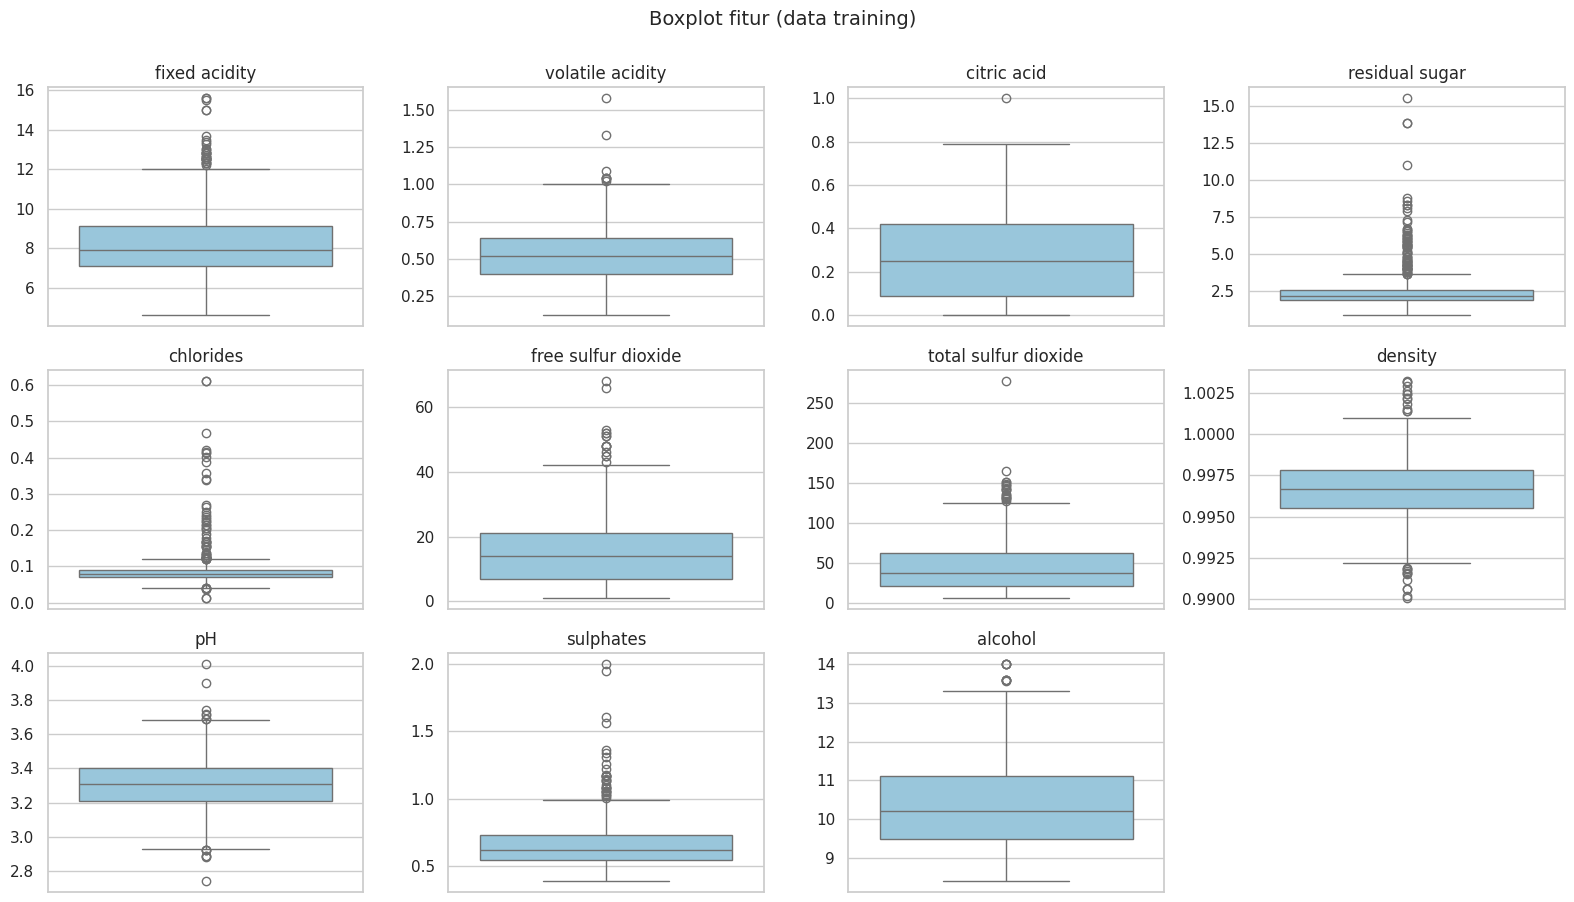

,batas_bawah,batas_atas,jumlah_outlier,persen
fitur,,,,
fixed acidity,4.1000,12.1000,30,3.5
volatile acidity,0.0275,1.0075,8,0.9
citric acid,-0.4050,0.9150,1,0.1
residual sugar,0.8500,3.6500,76,8.9
chlorides,0.0400,0.1200,59,6.9
free sulfur dioxide,-14.0000,42.0000,15,1.8
total sulfur dioxide,-42.0000,126.0000,19,2.2
density,0.9921,1.0012,25,2.9
pH,2.9250,3.6850,14,1.6


In [29]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(y=train[col], ax=ax, color="#8ecae6")
    ax.set_title(col)
    ax.set_ylabel("")
for ax in axes.ravel()[len(FEATURES):]:
    ax.axis("off")
plt.suptitle("Boxplot fitur (data training)", y=1.0, fontsize=14)
plt.tight_layout()
plt.show()

rows = []
for col in FEATURES:
    q1, q3 = train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((train[col] < low) | (train[col] > high)).sum())
    rows.append({"fitur": col, "batas_bawah": round(low, 4), "batas_atas": round(high, 4),
                 "jumlah_outlier": n_out, "persen": round(100 * n_out / len(train), 1)})
outlier_tbl = pd.DataFrame(rows).set_index("fitur")
outlier_tbl

### Interpretasi Bagian 2.2 (Outlier)

- Boxplot dan aturan IQR menunjukkan outlier terutama di sisi atas (nilai tinggi). Terbanyak: `residual sugar` (**76 baris, 8,9%**), `chlorides` (**59 baris, 6,9%**), `sulphates` (31), `fixed acidity` (30), dan `density` (25). `citric acid` hanya 1 baris. Batas bawah yang negatif pada beberapa fitur tidak mungkin tercapai, sehingga outlier hanya berada di sisi atas.
- **Keputusan: outlier tidak dihapus.** Alasannya:
  1. Data hanya 857 baris; menghapus outlier akan membuang cukup banyak sampel (`residual sugar` saja 8,9%).
  2. Nilai tinggi tersebut masih berada dalam rentang kadar kimia yang wajar. Apakah ada yang salah ukur adalah **[tidak terverifikasi]**.
  3. Data testing bisa saja memuat nilai ekstrem serupa, sehingga model perlu tetap mengenalnya.
  4. Model berbasis pohon (kandidat terkuat) memotong data berdasarkan urutan nilai, bukan jarak, sehingga relatif tahan terhadap outlier.
- Untuk model berbasis jarak (KNN, SVM), outlier bisa berpengaruh, tetapi akan dibantu oleh scaling di dalam Pipeline.

### 2.3 Distribusi target `quality` dan ketidakseimbangan kelas

,jumlah,persen
quality,,
3,6,0.7
4,26,3.0
5,362,42.2
6,341,39.8
7,109,12.7
8,13,1.5


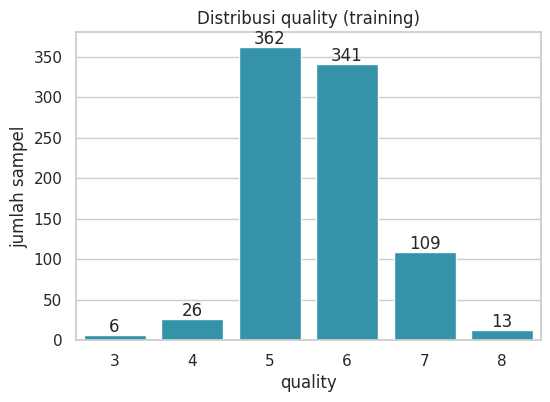

Akurasi baseline jika selalu menebak kelas mayoritas (5): 0.4224


In [30]:
dist = y.value_counts().sort_index()
dist_tbl = pd.DataFrame({"jumlah": dist, "persen": (100 * dist / len(y)).round(1)})
display(dist_tbl)

plt.figure(figsize=(6, 4))
ax = sns.barplot(x=dist.index, y=dist.values, color="#219ebc")
for i, v in enumerate(dist.values):
    ax.text(i, v + 4, str(v), ha="center")
plt.xlabel("quality"); plt.ylabel("jumlah sampel"); plt.title("Distribusi quality (training)")
plt.show()

print("Akurasi baseline jika selalu menebak kelas mayoritas (5):", round(dist.max() / len(y), 4))

### Interpretasi Bagian 2.3 (Distribusi `quality`)

- Kelas **5 (362 sampel, 42,2%)** dan **6 (341 sampel, 39,8%)** mencakup sekitar 82% data. Kelas 7 sebesar 12,7%, sedangkan kelas langka: **4 (26 sampel, 3,0%)**, **8 (13 sampel, 1,5%)**, dan **3 (hanya 6 sampel, 0,7%)**.
- Soal menyebut skala 0 sampai 10, tetapi data training hanya memuat kualitas **3 sampai 8**. Model hanya akan bisa memprediksi kelas yang pernah dilihat, yaitu 3 sampai 8.
- Data **sangat tidak seimbang**. Model cenderung memilih kelas 5 atau 6 karena paling sering muncul. Menebak selalu kelas 5 saja sudah menghasilkan **akurasi baseline 42,24%**. Karena itu akurasi saja bisa menyesatkan, dan **macro-F1** (rata-rata F1 semua kelas, termasuk yang langka) ikut dilaporkan.
- Penanganan yang dipakai: *Stratified* K-Fold agar proporsi kelas terjaga di setiap lipatan, serta pengujian parameter `class_weight` saat tuning (Bagian 3.2). Oversampling tidak dipakai karena di luar library yang diizinkan.

### 2.4 Skala fitur

In [31]:
skala = X.describe().T[["min", "max", "mean", "std"]].round(4)
skala["rentang"] = (skala["max"] - skala["min"]).round(4)
skala.sort_values("rentang", ascending=False)

,min,max,mean,std,rentang
total sulfur dioxide,6.0000,278.0000,45.9784,31.6921,272.0000
free sulfur dioxide,1.0000,68.0000,15.7830,10.3004,67.0000
residual sugar,0.9000,15.5000,2.5062,1.2935,14.6000
fixed acidity,4.6000,15.6000,8.2620,1.7020,11.0000
alcohol,8.4000,14.0000,10.4303,1.0670,5.6000
sulphates,0.3900,2.0000,0.6567,0.1674,1.6100
volatile acidity,0.1200,1.5800,0.5294,0.1792,1.4600
pH,2.7400,4.0100,3.3131,0.1521,1.2700
citric acid,0.0000,1.0000,0.2674,0.1951,1.0000
chlorides,0.0120,0.6110,0.0868,0.0487,0.5990


### Interpretasi Bagian 2.4 (Skala fitur)

- Skala antar fitur **sangat berbeda**. `total sulfur dioxide` berkisar 6 sampai 278 (rentang 272) dan `free sulfur dioxide` 1 sampai 68, sedangkan `density` hanya 0,990 sampai 1,003 (rentang 0,0131, simpangan baku 0,0019) dan `chlorides` 0,012 sampai 0,611.
- **Model yang butuh scaling:** KNN (menghitung jarak, sehingga fitur ber-skala besar seperti `total sulfur dioxide` akan mendominasi), SVM RBF (kernel berbasis jarak), dan Logistic Regression (regularisasi dan optimisasinya sensitif terhadap skala).
- **Model yang tidak butuh scaling:** Random Forest, Extra Trees, dan Gradient Boosting. Pohon hanya mencari ambang batas pada tiap fitur sehingga tidak terpengaruh skala.
- **Cara scaling:** `StandardScaler` (z-score) dipasang **di dalam `Pipeline`**. Dengan begitu rata-rata dan simpangan baku dihitung hanya dari data latih di setiap fold (tidak ada *data leakage*) dan diterapkan dengan cara yang sama saat prediksi data testing. Standardisasi dipilih daripada min-max karena min-max sangat dipengaruhi outlier, sedangkan outlier tidak dihapus.

## 3. Pembuatan Model

### 3.1 Perbandingan beberapa model dengan Stratified 5-Fold Cross-Validation

Setiap model dibungkus dalam `Pipeline` (`ColumnTransformer` lalu model). `ColumnTransformer` hanya mengambil 11 kolom fitur sehingga `Id` tidak mungkin ikut masuk. Untuk Logistic Regression, KNN, dan SVM ditambahkan `StandardScaler` **di dalam pipeline**, jadi scaling dihitung ulang hanya dari data latih tiap fold (tidak ada data leakage). Model berbasis pohon tidak memakai scaling.

In [32]:
def make_pipeline(model, scale):
    """Pipeline: pemilih kolom fitur (+ StandardScaler bila scale=True) -> model."""
    step = StandardScaler() if scale else "passthrough"
    prep = ColumnTransformer([("fitur", step, FEATURES)], remainder="drop")
    return Pipeline([("prep", prep), ("model", model)])

kandidat = {
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), scale=True),
    "KNN":                 make_pipeline(KNeighborsClassifier(), scale=True),
    "SVM (RBF)":           make_pipeline(SVC(random_state=RANDOM_STATE), scale=True),
    "Random Forest":       make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE), scale=False),
    "Gradient Boosting":   make_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE), scale=False),
    "Extra Trees":         make_pipeline(ExtraTreesClassifier(random_state=RANDOM_STATE), scale=False),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

hasil = []
for nama, pipe in kandidat.items():
    r = cross_validate(pipe, X, y, cv=cv, scoring=["accuracy", "f1_macro"])
    hasil.append({
        "Model": nama,
        "Akurasi CV (rata-rata)": r["test_accuracy"].mean(),
        "Akurasi CV (std)": r["test_accuracy"].std(),
        "Macro-F1 CV (rata-rata)": r["test_f1_macro"].mean(),
        "Macro-F1 CV (std)": r["test_f1_macro"].std(),
    })
tabel_cv = pd.DataFrame(hasil).sort_values("Akurasi CV (rata-rata)", ascending=False).reset_index(drop=True)
tabel_cv["Akurasi (mean ± std)"] = tabel_cv.apply(lambda r: f"{r['Akurasi CV (rata-rata)']:.4f} ± {r['Akurasi CV (std)']:.4f}", axis=1)
tabel_cv["Macro-F1 (mean ± std)"] = tabel_cv.apply(lambda r: f"{r['Macro-F1 CV (rata-rata)']:.4f} ± {r['Macro-F1 CV (std)']:.4f}", axis=1)
display(tabel_cv[["Model", "Akurasi (mean ± std)", "Macro-F1 (mean ± std)"]])
print("Baseline kelas mayoritas (akurasi):", round((y == y.mode()[0]).mean(), 4))

,Model,Akurasi (mean ± std),Macro-F1 (mean ± std)
0,Extra Trees,0.6430 ± 0.0295,0.3424 ± 0.0437
1,Random Forest,0.6430 ± 0.0262,0.3483 ± 0.0410
2,SVM (RBF),0.6091 ± 0.0330,0.2771 ± 0.0172
3,Gradient Boosting,0.6079 ± 0.0137,0.3384 ± 0.0346
4,Logistic Regression,0.5951 ± 0.0451,0.2740 ± 0.0216
5,KNN,0.5567 ± 0.0604,0.2640 ± 0.0259


Baseline kelas mayoritas (akurasi): 0.4224


### Interpretasi Bagian 3.1 (Perbandingan model)

- **Extra Trees** dan **Random Forest** menempati posisi teratas dengan akurasi CV yang sama, **0,6430** (±0,0295 dan ±0,0262). Di bawahnya: SVM RBF 0,6091, Gradient Boosting 0,6079, Logistic Regression 0,5951, dan KNN terendah 0,5567 dengan simpangan baku terbesar (±0,0604).
- Semua model mengalahkan baseline kelas mayoritas (0,4224), jadi fitur kimia memang membawa informasi tentang kualitas.
- **Macro-F1 semua model rendah (sekitar 0,26 sampai 0,35)**. Ini menunjukkan model sulit mengenali kelas langka, yang sejalan dengan masalah ketidakseimbangan kelas di Bagian 2.3.
- Model ensemble berbasis pohon unggul kemungkinan karena hubungan fitur kimia dengan kualitas tidak linear dan pohon tidak sensitif terhadap skala maupun outlier. Ini dugaan dari hasil, bukan hasil pengujian khusus.
- Selisih Extra Trees dan Random Forest jauh lebih kecil daripada simpangan baku antar fold, jadi **keduanya dipilih untuk dituning**. Pemilihan memakai akurasi CV karena penilaian soal memakai akurasi.

### 3.2 Hyperparameter tuning

Dua model dengan akurasi CV tertinggi dituning dengan `RandomizedSearchCV` (5-fold stratified, skor = akurasi karena penilaian memakai akurasi). Pilihan `class_weight` (`None`, `balanced`, `balanced_subsample`) ikut dicari supaya terbukti apakah pembobotan kelas membantu atau tidak.

In [33]:
dua_terbaik = tabel_cv["Model"].head(2).tolist()
print("Dua model untuk dituning:", dua_terbaik)

ruang_param = {
    "Random Forest": {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [None, 8, 12, 16, 24],
        "model__min_samples_split": [2, 4, 6, 10],
        "model__min_samples_leaf": [1, 2, 3, 4],
        "model__max_features": ["sqrt", "log2", 0.5],
        "model__class_weight": [None, "balanced", "balanced_subsample"],
    },
    "Extra Trees": {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [None, 8, 12, 16, 24],
        "model__min_samples_split": [2, 4, 6, 10],
        "model__min_samples_leaf": [1, 2, 3, 4],
        "model__max_features": ["sqrt", "log2", 0.5],
        "model__class_weight": [None, "balanced", "balanced_subsample"],
    },
}

hasil_tuning, searches = [], {}
for nama in dua_terbaik:
    s = RandomizedSearchCV(kandidat[nama], ruang_param[nama], n_iter=30, scoring="accuracy",
                           cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
    s.fit(X, y)
    searches[nama] = s
    awal = tabel_cv.set_index("Model").loc[nama, "Akurasi CV (rata-rata)"]
    hasil_tuning.append({"Model": nama, "Akurasi CV default": round(awal, 4),
                         "Akurasi CV setelah tuning": round(s.best_score_, 4)})
    print(f"\n{nama}\n  parameter terbaik: {s.best_params_}")
display(pd.DataFrame(hasil_tuning))

Dua model untuk dituning: ['Extra Trees', 'Random Forest']

Extra Trees
  parameter terbaik: {'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': None, 'model__class_weight': None}

Random Forest
  parameter terbaik: {'model__n_estimators': 300, 'model__min_samples_split': 4, 'model__min_samples_leaf': 1, 'model__max_features': 'log2', 'model__max_depth': 16, 'model__class_weight': 'balanced'}


,Model,Akurasi CV default,Akurasi CV setelah tuning
0,Extra Trees,0.643,0.6523
1,Random Forest,0.643,0.6500


In [34]:
# Apakah class_weight membantu? Rata-rata akurasi CV semua kandidat dari pencarian, dikelompokkan per class_weight
for nama, s in searches.items():
    cvr = pd.DataFrame(s.cv_results_)
    cvr["class_weight"] = cvr["param_model__class_weight"].apply(lambda v: "None" if (v is None or pd.isna(v)) else str(v))
    print(nama)
    print(cvr.groupby("class_weight")["mean_test_score"].agg(["mean", "max", "count"]).round(4), "\n")

# Pilih model final = akurasi CV tertinggi setelah tuning
nama_final = max(searches, key=lambda k: searches[k].best_score_)
pipeline_final = searches[nama_final].best_estimator_
print("MODEL FINAL:", nama_final)
print("Akurasi CV (tuned):", round(searches[nama_final].best_score_, 4))
print("Parameter:", searches[nama_final].best_params_)

Extra Trees
                      mean     max  count
class_weight                             
None                0.6307  0.6523      9
balanced            0.6038  0.6430      9
balanced_subsample  0.5867  0.6290     12 

Random Forest
                      mean     max  count
class_weight                             
None                0.6299  0.6418      9
balanced            0.6277  0.6500      9
balanced_subsample  0.6176  0.6418     12 

MODEL FINAL: Extra Trees
Akurasi CV (tuned): 0.6523
Parameter: {'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': None, 'model__class_weight': None}


In [35]:
# Skor CV model final dengan metrik lengkap (akurasi dan macro-F1, rata-rata ± std)
r_final = cross_validate(clone(pipeline_final), X, y, cv=cv, scoring=["accuracy", "f1_macro"])
cv_acc_mean, cv_acc_std = r_final["test_accuracy"].mean(), r_final["test_accuracy"].std()
cv_f1_mean, cv_f1_std = r_final["test_f1_macro"].mean(), r_final["test_f1_macro"].std()
print(f"Akurasi  CV 5-fold: {cv_acc_mean:.4f} ± {cv_acc_std:.4f}")
print(f"Macro-F1 CV 5-fold: {cv_f1_mean:.4f} ± {cv_f1_std:.4f}")

Akurasi  CV 5-fold: 0.6523 ± 0.0299
Macro-F1 CV 5-fold: 0.3476 ± 0.0412


### Interpretasi Bagian 3.2 (Tuning dan model final)

- Setelah tuning (30 kombinasi, 5-fold), akurasi CV naik dari 0,6430 menjadi **0,6523** untuk Extra Trees dan **0,6500** untuk Random Forest. Kenaikannya sekitar 1 poin persen, **lebih kecil daripada simpangan baku antar fold (sekitar 0,03)**, jadi perbaikannya kecil. Skor setelah tuning juga cenderung sedikit optimis karena dipilih sebagai yang terbaik dari 30 kandidat pada pembagian fold yang sama.
- **Pengaruh `class_weight`:** untuk Extra Trees, rata-rata akurasi tanpa pembobotan (0,6307) lebih tinggi daripada `balanced` (0,6038) dan `balanced_subsample` (0,5867). Untuk Random Forest, tanpa pembobotan (0,6299) dan `balanced` (0,6277) hampir sama; `balanced` memberi skor tertinggi Random Forest (0,6500) tetapi tidak melampaui Extra Trees. Jadi `class_weight` **tidak terbukti membantu akurasi** dan tidak dipakai pada model final.
- **Model final: Extra Trees** dengan `n_estimators=200`, `max_features=0.5`, `max_depth=None`, `min_samples_split=2`, `min_samples_leaf=1`, `class_weight=None`.
- Estimasi performa model final dengan CV 5-fold: **akurasi 0,6523 ± 0,0299** dan **macro-F1 0,3476 ± 0,0412**.

## 4. Evaluasi Model

Evaluasi memakai **hold-out stratified 80/20** dari data training: model dilatih pada 80% data, lalu diuji pada 20% data yang belum pernah dilihat. Data testing (tanpa label) tidak dipakai untuk menghitung akurasi.

In [36]:
X_tr, X_ho, y_tr, y_ho = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Data latih:", X_tr.shape, "| Data hold-out:", X_ho.shape)
print("Distribusi quality di hold-out:", y_ho.value_counts().sort_index().to_dict())

model_ho = clone(pipeline_final).fit(X_tr, y_tr)
pred_ho = model_ho.predict(X_ho)

ho_acc = accuracy_score(y_ho, pred_ho)
ho_f1 = f1_score(y_ho, pred_ho, average="macro")
print(f"\nAkurasi hold-out : {ho_acc:.4f}")
print(f"Macro-F1 hold-out: {ho_f1:.4f}")

# Baseline: selalu menebak kelas mayoritas
base = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
base_pred = base.predict(X_ho)
base_acc = accuracy_score(y_ho, base_pred)
base_f1 = f1_score(y_ho, base_pred, average="macro", zero_division=0)
print(f"\nBaseline (kelas mayoritas) -> akurasi: {base_acc:.4f} | macro-F1: {base_f1:.4f}")
print(f"Selisih akurasi model vs baseline: {ho_acc - base_acc:+.4f}")

Data latih: (685, 11) | Data hold-out: (172, 11)
Distribusi quality di hold-out: {3: 1, 4: 5, 5: 73, 6: 68, 7: 22, 8: 3}

Akurasi hold-out : 0.5988
Macro-F1 hold-out: 0.3545

Baseline (kelas mayoritas) -> akurasi: 0.4244 | macro-F1: 0.0993
Selisih akurasi model vs baseline: +0.1744


In [37]:
print(classification_report(y_ho, pred_ho, zero_division=0, digits=3))

              precision    recall  f1-score   support

           3      0.000     0.000     0.000         1
           4      0.000     0.000     0.000         5
           5      0.644     0.767     0.700        73
           6      0.580     0.588     0.584        68
           7      0.462     0.273     0.343        22
           8      1.000     0.333     0.500         3

    accuracy                          0.599       172
   macro avg      0.447     0.327     0.354       172
weighted avg      0.579     0.599     0.581       172



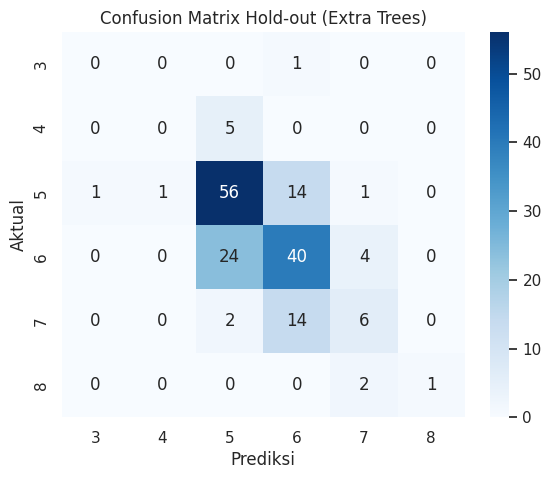

In [38]:
kelas = sorted(y.unique())
cm = confusion_matrix(y_ho, pred_ho, labels=kelas)
plt.figure(figsize=(6.5, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=kelas, yticklabels=kelas)
plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.title(f"Confusion Matrix Hold-out ({nama_final})")
plt.show()

In [39]:
# Seberapa banyak baris hold-out yang fiturnya identik dengan baris di data latih (80%)?
kunci_latih = set(map(tuple, X_tr.round(6).values))
n_kembar = sum(tuple(r) in kunci_latih for r in X_ho.round(6).values)
print(f"Baris hold-out dengan fitur identik pada data latih: {n_kembar} dari {len(X_ho)}")

Baris hold-out dengan fitur identik pada data latih: 32 dari 172


,importance
alcohol,0.1487
sulphates,0.1199
volatile acidity,0.1072
total sulfur dioxide,0.0937
chlorides,0.0799
citric acid,0.0795
density,0.0763
fixed acidity,0.0745
residual sugar,0.0740
pH,0.0734


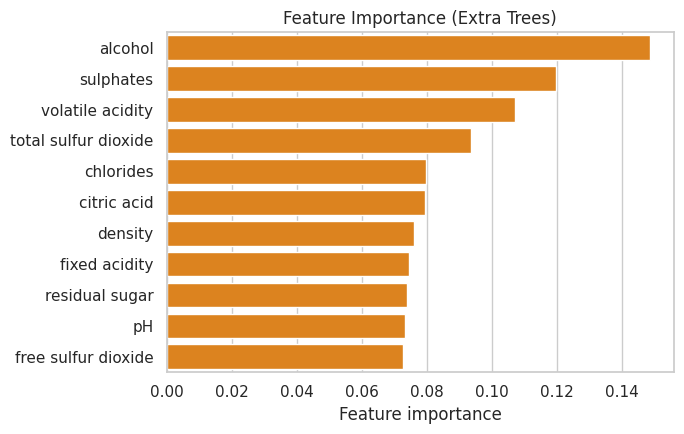

In [40]:
# Feature importance dari model hold-out (model berbasis pohon)
imp = pd.Series(model_ho.named_steps["model"].feature_importances_, index=FEATURES).sort_values(ascending=False)
display(imp.round(4).to_frame("importance"))

plt.figure(figsize=(7, 4.5))
sns.barplot(x=imp.values, y=imp.index, color="#fb8500")
plt.xlabel("Feature importance"); plt.ylabel("")
plt.title(f"Feature Importance ({nama_final})")
plt.tight_layout(); plt.show()

### Interpretasi Bagian 4 (Evaluasi)

**Skor hold-out (20% data = 172 baris).** Akurasi **0,5988** dan macro-F1 **0,3545**. Baseline kelas mayoritas hanya mencapai akurasi 0,4244 dan macro-F1 0,0993, sehingga model unggul sekitar **17 poin persen** dalam akurasi. Skor hold-out lebih rendah daripada CV (0,6523). Selisih sekitar 5 poin setara sekitar 9 sampel dari 172, masih wajar karena hold-out kecil dan skor CV setelah tuning sedikit optimis. Perkiraan yang lebih jujur untuk akurasi pada data baru adalah **sekitar 0,60 sampai 0,65**.

**Kelas mana yang sering salah?** Dari confusion matrix dan classification report:
- **Kelas 5**: 56 dari 73 benar (recall 0,767). Kesalahan terbanyak diprediksi sebagai kelas 6.
- **Kelas 6**: 40 dari 68 benar (recall 0,588). Sebanyak 24 diprediksi sebagai 5 dan 4 sebagai 7.
- **Kelas 7**: hanya 6 dari 22 benar (recall 0,273). Sebanyak 14 diprediksi sebagai 6.
- **Kelas 4**: semua 5 sampel salah (diprediksi kelas 5), sehingga F1 = 0.
- **Kelas 3**: satu-satunya sampel salah (diprediksi kelas 6), F1 = 0.
- **Kelas 8**: 1 dari 3 benar dan 2 diprediksi kelas 7. Presisi 1,000 dan recall 0,333 hanya berasal dari 3 sampel, sehingga angkanya tidak stabil.

**Mengapa begitu?** (1) Kesalahan paling banyak terjadi antar kelas bertetangga (5 dengan 6, 6 dengan 7). Kualitas bersifat berurutan dan sifat kimia anggur bertetangga saling tumpang tindih, sehingga sulit dipisahkan. (2) Kelas langka 3, 4, dan 8 hanya punya 6, 26, dan 13 sampel di training (di hold-out hanya 1, 5, dan 3 sampel), sehingga model nyaris tidak punya contoh untuk mempelajarinya dan cenderung menebak kelas besar. Karena F1 kelas 3 dan 4 bernilai 0, macro-F1 ikut rendah.

**Catatan duplikat:** 32 dari 172 baris hold-out punya fitur identik dengan baris di data latih. Hal ini bisa membuat skor hold-out sedikit lebih optimis (lihat Bagian 2.1).

**Feature importance.** Fitur paling berpengaruh: **`alcohol` (0,149)**, lalu **`sulphates` (0,120)**, **`volatile acidity` (0,107)**, dan **`total sulfur dioxide` (0,094)**. Tujuh fitur lainnya berada pada kisaran 0,073 sampai 0,080 dan hampir setara. Jadi kadar alkohol, sulphates, dan keasaman volatil paling membantu model membedakan kualitas. Perlu diingat bahwa importance hanya menunjukkan fitur yang berguna untuk prediksi, bukan hubungan sebab-akibat, dan tidak menunjukkan arah pengaruhnya.

## 5. Simpan Model dan Deployment

Pipeline final dilatih ulang pada **seluruh** data training, disimpan dengan `joblib`, lalu dimuat kembali dari file untuk memprediksi `data_testing.csv`.

In [41]:
model_akhir = clone(pipeline_final).fit(X, y)       # seluruh 857 baris training
joblib.dump(model_akhir, "model_wine_quality.joblib")
print("Model disimpan ke model_wine_quality.joblib")

model_dimuat = joblib.load("model_wine_quality.joblib")  # muat ulang dari file
print("Model berhasil dimuat ulang:", type(model_dimuat).__name__)
print(model_dimuat)

# Deployment: prediksi data testing (Id ikut diberikan, tetapi ColumnTransformer hanya memakai 11 fitur)
pred_test = model_dimuat.predict(test)
print("\nJumlah prediksi:", len(pred_test))

Model disimpan ke model_wine_quality.joblib
Model berhasil dimuat ulang: Pipeline
Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('fitur', 'passthrough',
                                                  ['fixed acidity',
                                                   'volatile acidity',
                                                   'citric acid',
                                                   'residual sugar',
                                                   'chlorides',
                                                   'free sulfur dioxide',
                                                   'total sulfur dioxide',
                                                   'density', 'pH', 'sulphates',
                                                   'alcohol'])])),
                ('model',
                 ExtraTreesClassifier(max_features=0.5, n_estimators=200,
                                      random_state=42))])

Jumlah prediksi: 286


### Interpretasi Bagian 5 (Simpan model dan deployment)

- Pipeline final dilatih ulang pada **seluruh 857 baris** training, lalu disimpan ke `model_wine_quality.joblib`. Karena semua data sudah terpakai, tidak ada data tersisa untuk menguji model ini; performanya diperkirakan serupa dengan hasil CV dan hold-out di Bagian 3 dan 4.
- Model berhasil **dimuat ulang dari file**. Isinya adalah `Pipeline` berisi `ColumnTransformer` yang hanya memilih 11 fitur (tahap `passthrough` karena Extra Trees tidak butuh scaling) dan `ExtraTreesClassifier`.
- Saat deployment, seluruh tabel testing (termasuk `Id`) diberikan ke pipeline, tetapi `ColumnTransformer` membuang kolom selain 11 fitur (`remainder="drop"`). Dengan begitu `Id` tidak pernah dipakai sebagai fitur. Hasilnya adalah **286 prediksi**, sesuai jumlah baris data testing.

## 6. Hasil Prediksi

File hasil prediksi hanya berisi dua kolom, `Id` dan `Quality` (bilangan bulat), dengan urutan baris sama dengan `data_testing.csv`, pemisah titik koma (`;`), dan tanpa kolom indeks, sesuai template.

In [42]:
NIM_3_DIGIT = "003"
NAMA_FILE = f"hasilprediksi_{NIM_3_DIGIT}.csv"

hasil_prediksi = pd.DataFrame({"Id": id_test.values, "Quality": pred_test.astype(int)})
hasil_prediksi.to_csv(NAMA_FILE, sep=";", index=False, lineterminator="\r\n")  # CRLF sama seperti template
print("Disimpan:", NAMA_FILE)
hasil_prediksi.head(10)

Disimpan: hasilprediksi_003.csv


,Id,Quality
0,222,5
1,1514,6
2,417,5
3,754,5
4,516,5
5,1120,6
6,180,5
7,82,5
8,632,5
9,592,5


,training (%),prediksi testing (%),prediksi testing (jumlah)
3,0.7,0.0,0.0
4,3.0,0.3,1.0
5,42.2,47.2,135.0
6,39.8,41.3,118.0
7,12.7,11.2,32.0
8,1.5,0.0,0.0


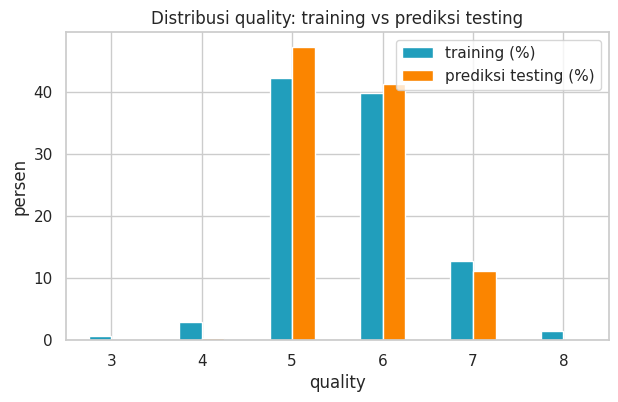

In [43]:
# Sanity check: distribusi prediksi vs distribusi training
bandingkan = pd.DataFrame({
    "training (%)": (100 * y.value_counts(normalize=True)).round(1),
    "prediksi testing (%)": (100 * hasil_prediksi["Quality"].value_counts(normalize=True)).round(1),
    "prediksi testing (jumlah)": hasil_prediksi["Quality"].value_counts(),
}).sort_index().fillna(0)
display(bandingkan)

bandingkan[["training (%)", "prediksi testing (%)"]].plot(kind="bar", figsize=(7, 4), color=["#219ebc", "#fb8500"])
plt.xlabel("quality"); plt.ylabel("persen"); plt.title("Distribusi quality: training vs prediksi testing")
plt.xticks(rotation=0); plt.show()

In [44]:
# Validasi format file hasil
template_id = test[ID_COL].tolist()
cek = pd.read_csv(NAMA_FILE, sep=";")
with open(NAMA_FILE, "rb") as f:
    header = f.readline().decode().strip()

print("Header file               :", header)
print("Jumlah baris data         :", len(cek), "(harus 286)")
print("Jumlah kolom              :", cek.shape[1], "(harus 2)")
print("Nilai kosong              :", int(cek.isna().sum().sum()), "(harus 0)")
print("Tipe Quality              :", cek["Quality"].dtype)
print("Rentang Quality           :", cek["Quality"].min(), "-", cek["Quality"].max(), "(harus 3-8)")
print("Id sama & urutan sama     :", cek["Id"].tolist() == template_id)
print("Prediksi file == prediksi model (dimuat ulang):", bool((cek["Quality"].values == model_dimuat.predict(test)).all()))

assert header == "Id;Quality" and len(cek) == 286 and cek.shape[1] == 2
assert cek.isna().sum().sum() == 0 and pd.api.types.is_integer_dtype(cek["Quality"])
assert cek["Quality"].between(3, 8).all() and cek["Id"].tolist() == template_id
assert (cek["Quality"].values == model_dimuat.predict(test)).all()
print("\nSemua pengecekan format LULUS.")

Header file               : Id;Quality
Jumlah baris data         : 286 (harus 286)
Jumlah kolom              : 2 (harus 2)
Nilai kosong              : 0 (harus 0)
Tipe Quality              : int64
Rentang Quality           : 4 - 7 (harus 3-8)
Id sama & urutan sama     : True
Prediksi file == prediksi model (dimuat ulang): True

Semua pengecekan format LULUS.


### Interpretasi Bagian 6 (Hasil prediksi)

- **Distribusi prediksi** pada testing: kelas 5 sebanyak 135 (47,2%), kelas 6 sebanyak 118 (41,3%), kelas 7 sebanyak 32 (11,2%), dan kelas 4 hanya 1 (0,3%). Kelas 3 dan 8 **tidak pernah diprediksi**.
- Dibandingkan dengan training (5: 42,2%, 6: 39,8%, 7: 12,7%, 4: 3,0%, 3: 0,7%, 8: 1,5%), pola umumnya mirip. Bedanya, prediksi sedikit lebih condong ke kelas 5 dan 6, dan kelas langka hampir tidak muncul. Ini sesuai dengan hasil hold-out di Bagian 4. Jika data kunci memuat kualitas 3 atau 8, prediksi untuk baris itu pasti salah.
- Sanity check ini menunjukkan prediksi masuk akal, **tetapi bukan bukti akurasi**, karena data testing tidak berlabel.
- **Validasi format file lulus:** header `Id;Quality`, 286 baris data, 2 kolom, tanpa nilai kosong, `Quality` bilangan bulat dengan nilai 4 sampai 7 (di dalam rentang 3 sampai 8), `Id` dan urutannya sama dengan `data_testing.csv`, dan isinya identik dengan prediksi model yang dimuat ulang dari file `.joblib`.

## 7. Kesimpulan

**Model terpilih.** Extra Trees (200 pohon, `max_features=0.5`, tanpa `class_weight`) dalam `Pipeline`, dilatih pada seluruh data training. Model ini dipilih karena akurasi CV tertingginya (0,6523) setelah dibandingkan dengan enam model dan dituning bersama Random Forest.

**Estimasi performa** (dari data training, bukan klaim atas data testing):

| Ukuran | Akurasi | Macro-F1 |
|---|---|---|
| CV 5-fold (rata-rata ± std) | 0,6523 ± 0,0299 | 0,3476 ± 0,0412 |
| Hold-out 20% (172 baris) | 0,5988 | 0,3545 |
| Baseline kelas mayoritas (hold-out) | 0,4244 | 0,0993 |

Perkiraan akurasi pada data baru adalah sekitar **0,60 sampai 0,65**. Faktor yang paling berpengaruh pada prediksi adalah `alcohol`, `sulphates`, dan `volatile acidity`.

**Keterbatasan**
1. Data sangat tidak seimbang. Kelas 3, 4, dan 8 hampir tidak pernah diprediksi benar sehingga macro-F1 hanya sekitar 0,35.
2. Ada baris dengan fitur kembar di training dan antara training dengan testing, sehingga skor CV dan hold-out bisa sedikit optimis.
3. Hold-out hanya 172 baris (kelas 3 hanya 1 sampel), sehingga angka per kelas tidak stabil.
4. Tuning terbatas pada 30 kombinasi, dan kenaikan akurasinya lebih kecil daripada variasi antar fold.
5. Model memperlakukan `quality` sebagai kategori biasa tanpa memanfaatkan urutannya, dan feature importance tidak menunjukkan sebab-akibat.

**Saran perbaikan**
- Menangani ketidakseimbangan dengan oversampling (misalnya SMOTE) atau menggabungkan kelas langka, lalu menilai dengan macro-F1 juga.
- Mencoba pendekatan yang memanfaatkan urutan kualitas (misalnya regresi ordinal) dan rekayasa fitur (misalnya rasio `free sulfur dioxide` terhadap `total sulfur dioxide`).
- Mencoba model boosting lain seperti XGBoost atau LightGBM, serta *repeated* CV agar estimasi lebih stabil.
- Menempatkan baris kembar dalam fold yang sama (misalnya dengan `GroupKFold`) agar estimasi performa lebih jujur.
- Menambah jumlah data, terutama untuk kualitas rendah dan tinggi.